# Coverage: main workflow

## 1. Paths and processing settings

- Use **Python (crystal_seg)**; run cells in order from `coverage/` or the project root.
- Set the source folder, plates and number of images in `CONFIG`.
- Use a new `RUN_DIR` for a different dataset/settings; existing manual entries are preserved.
- Current selection: 36 plates / 287 images; outputs: `output/analysis_001/`.

In [1]:
# Cell 1: Set paths and processing parameters.
from pathlib import Path
import sys

# Run from coverage/ or its parent project directory.
COVERAGE_DIR = Path.cwd().resolve()
if not (COVERAGE_DIR / "coverage_refactored.ipynb").is_file():
    COVERAGE_DIR = COVERAGE_DIR / "coverage"
if not (COVERAGE_DIR / "coverage_refactored.ipynb").is_file():
    raise FileNotFoundError("Start Jupyter from coverage/ or its parent directory.")
PROJECT_ROOT = COVERAGE_DIR.parent
sys.path.insert(0, str(COVERAGE_DIR))
RUN_DIR = COVERAGE_DIR / "output" / "analysis_001"
CONFIG = {
    "data_dir": "data/mag2000",
    "target_plates": {'new': ['pl01', 'pl02', 'pl04', 'pl05', 'pl06', 'pl07', 'pl08', 'pl09', 'pl10', 'pl11', 'pl12', 'pl13', 'pl14', 'pl15', 'pl16', 'pl17', 'pl18', 'pl19'], 'old': ['pl01', 'pl02', 'pl04', 'pl07', 'pl08', 'pl09', 'pl11', 'pl13', 'pl14', 'pl15', 'pl17', 'pl18', 'pl19', 'pl21', 'pl22', 'pl23', 'pl24', 'pl27']},
    "images_per_plate": 8,  # All available images; new/pl13 contains seven.
    "crop": {"top": 60, "bottom": 100, "left": 60, "right": 100},
    "max_sample_pixels": 10000, "predict_chunk_size": 200000, "random_state": 0,
}
DATA_DIR = PROJECT_ROOT / CONFIG["data_dir"]
print(f"Project: {PROJECT_ROOT}\nCoverage images: {DATA_DIR}\nRun: {RUN_DIR}")
print(f"Input directory exists: {DATA_DIR.is_dir()}")

PHOTON_YIELD_PATH = PROJECT_ROOT / "implement" / "data" / "tables" / "photon_yield.csv"


Project: /home/kmanabe2403/dune
Coverage images: /home/kmanabe2403/dune/data/mag2000
Run: /home/kmanabe2403/dune/coverage/output/analysis_001
Input directory exists: True


## 2. Select images

- Run this cell to save the image list and processing settings in `metadata/`.
- Check the selected image count before continuing.

In [2]:
# Cell 2: Select images and save the manifest and settings (original Cell 2).
# Use a new RUN_DIR when changing input images or processing parameters.
from coverage_pipeline import prepare_run

prepare_run(PROJECT_ROOT, RUN_DIR, CONFIG)

Selected 287 images. Metadata: /home/kmanabe2403/dune/coverage/output/analysis_001/metadata


## 3. Crop images

- Save full-resolution crops using the margins in Cell 1; no resizing.
- Outputs: `images/image_XXXX.npy`.

In [3]:
# Cell 3: Crop and save each image separately (original Cell 3).
from coverage_pipeline import crop_images

crop_images(PROJECT_ROOT, RUN_DIR)

Saved 287 cropped images: /home/kmanabe2403/dune/coverage/output/analysis_001/images


## 4. Pixel features and GMM

- Calculate six pixel features; fit on up to 10,000 sampled pixels and classify every cropped pixel.
- Methods: 2 clusters, 4 clusters, hierarchical 2→2; no PCA in this main workflow.
- Save all label maps and cluster fractions in `gmm/`; progress is printed every 20 images and at completion.
- Rerunning overwrites the GMM results; review manual selections again if settings change.

In [4]:
# Cell 4: Run pixel GMM with 2, 4, and hierarchical 2 -> 2 clusters (original Cell 4).
# Save label maps and area ratios per image. Rerunning rebuilds the result CSV.
from coverage_pipeline import run_gmm

GMM_AREA_PATH = run_gmm(RUN_DIR, report_every=20)

Saved GMM results retained for all 287 images; calculations unchanged. On rerun, progress is reported every 20 images and at completion.


## 5. Review GMM results

- Save a comparison for every image in `review/figures/`; display one example here.
- Progress is printed every 20 images and at completion.
- Inspect these figures to choose the GMM method and clusters representing empty regions.

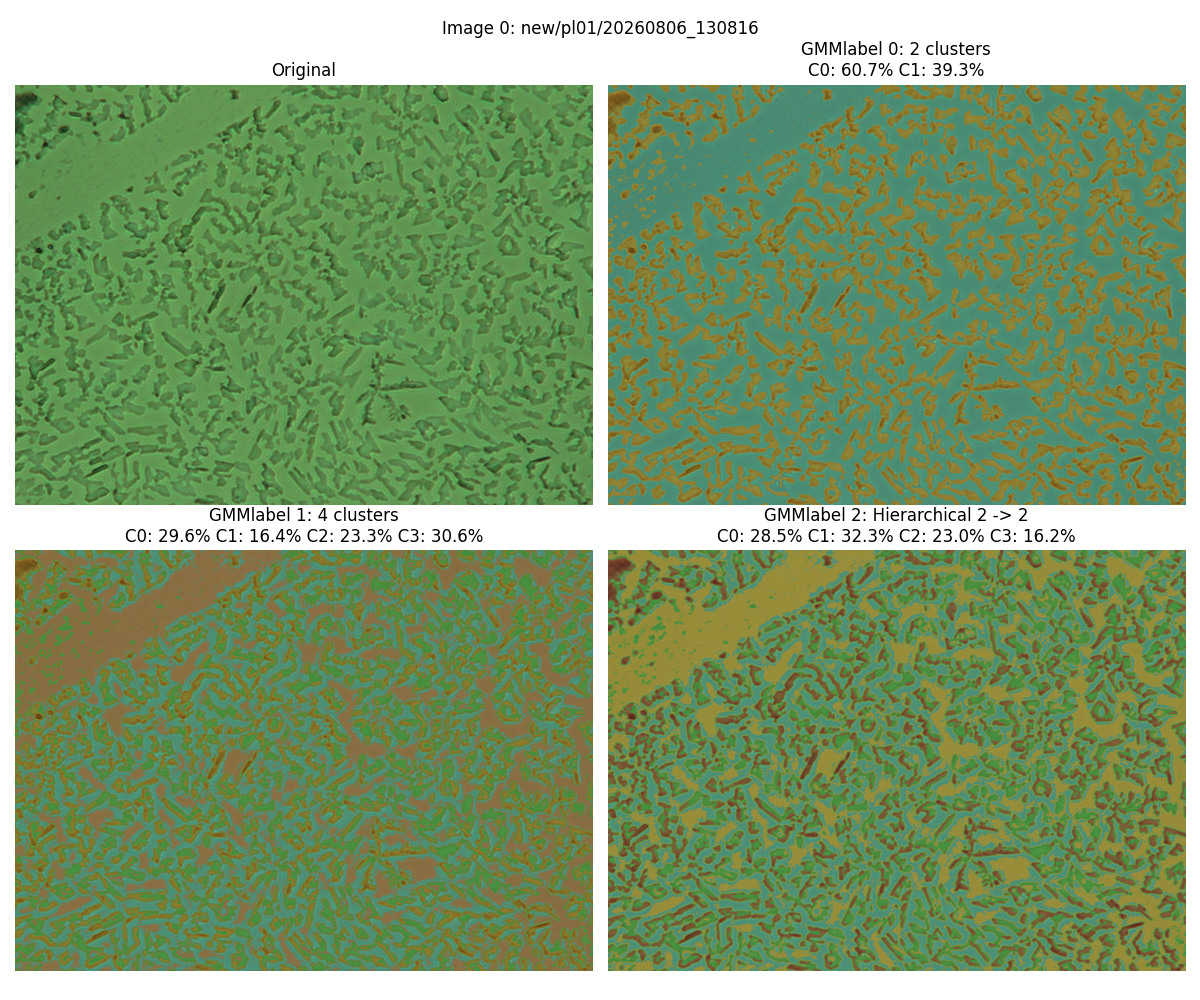

Review figures saved: 1/1


One image example refreshed; all 287 saved comparison figures retained. Full reruns report every 20 images and at completion.


In [5]:
# Cell 5: Inspect and save the three GMM comparisons (original Cell 4).
from coverage_analysis import show_gmm

show_gmm(RUN_DIR, image_ids=None, max_display=1, report_every=20)  # Save all comparison PNGs; display one example.

## 6. Enter empty-area selections

- Run this cell to create `review/gmm_settings.csv`; existing entries are kept.
- Inspect Cell 5 result `review/figures/` and edit the CSV:
  - `GMMlabel`: 0 = 2 clusters; 1 = 4 clusters; 2 = hierarchical 2→2.
  - `cluster`: empty cluster IDs, e.g. `0` or `"0,2"`.
  - Alternatively, enter a manual empty fraction (0–1) in `fluction`; leave `cluster` blank.
- `fluction` is normally blank when selecting clusters; calculated fractions appear in `empty_ratio` in Cell 7.
- Unselected rows are skipped. We can remove the pictures which are not well distinguish empty/cluster regions. 
- Save the CSV before running Cells 7–8.
- Optional plate-level manual fractions: `review/plate_manual_settings.csv`; these are separate from image measurements.

In [6]:
# Cell 6: Create editable settings; preserve any values already entered.
# Inspect Cell 5 and edit review/gmm_settings.csv before running Cells 7–8.
from coverage_pipeline import prepare_settings

GMM_SETTINGS_PATH = prepare_settings(RUN_DIR)
# GMMlabel: 0 = two clusters, 1 = four clusters, 2 = hierarchical 2 -> 2.
# cluster: comma-separated IDs of empty regions, e.g. "0,2".
# Alternatively enter an empty fraction (0–1) in fluction.
# Optional plate-level manual values: review/plate_manual_settings.csv.

Inspect Cell 5, then enter GMMlabel and empty cluster IDs in the CSV. Rerun Cells 7–8 after editing.
Edit cluster (comma-separated IDs) or fluction (manual empty fraction, 0–1): /home/kmanabe2403/dune/coverage/output/analysis_001/review/gmm_settings.csv
GMMlabel: 0 = two clusters; 1 = four clusters; 2 = hierarchical 2 -> 2. Existing settings are preserved.


## 7. Calculate coverage

- Coverage = 1 − empty pixel fraction; cluster selections take precedence over `fluction`.
- Display the first five image rows and five plate rows as examples; full tables are saved in `coverage/`.
- `empty_ratio` and `coverage` contain the calculated results; `fluction` records manual input only.
- Plate/source means require at least two selected images. Ranges use leave-one-image-out means, not confidence intervals.
- Separate plate-level manual values have no image-derived uncertainty.

In [7]:
# Cell 7: Calculate image coverage and plate summaries (original Cell 6).
# Skip unselected images. Summarize plates with at least two selected images.
import pandas as pd
from IPython.display import display
from coverage_analysis import calculate_coverage

PLATE_COVERAGE_PATH = calculate_coverage(RUN_DIR)
print("Image examples (first 5):")
display(pd.read_csv(RUN_DIR / "coverage" / "image_coverage.csv").head(5))
print("Plate examples (first 5):")
display(pd.read_csv(PLATE_COVERAGE_PATH).head(5))

,image_id,group,plate,name,gmm_label,cluster,fluction,empty_ratio,coverage,source
0,0,new,pl01,20260806_130816,0.0,0,NaN,0.607135,0.392865,cluster
1,1,new,pl01,20260806_130916,0.0,0,NaN,0.651748,0.348252,cluster
2,2,new,pl01,20260806_131002,2.0,"0,2",NaN,0.619377,0.380623,cluster
3,4,new,pl01,20260806_131117,0.0,1,NaN,0.572105,0.427895,cluster
4,6,new,pl01,20260806_131234,0.0,1,NaN,0.567040,0.432960,cluster


,group,plate,source,coverage,coverage_min,coverage_max,n_images
0,new,pl01,cluster,0.404164,0.396519,0.415346,6
1,new,pl02,cluster,0.667312,0.650345,0.691726,7
2,new,pl04,cluster,0.568391,0.557995,0.590941,8
3,new,pl05,cluster,0.470541,0.456948,0.497789,6
4,new,pl06,cluster,0.432286,0.413071,0.443654,5


Coverage: 100 images; 25 plate/source groups; 187 unselected images.
Plate summaries require at least two selected images per plate and source.
Image examples (first 5):
Plate examples (first 5):


## 8. Compare coverage with photon yield

- Join cluster-based plate means to the shared photon-yield table and fit a line.
- Manual plate values are excluded from this fit; missing selections are not filled automatically.
- Output: `coverage/coverage_vs_photon_yield.*`, `photon_comparison.csv`, `linear_fit.csv`.
- R² describes this fitted dataset, not held-out prediction accuracy.

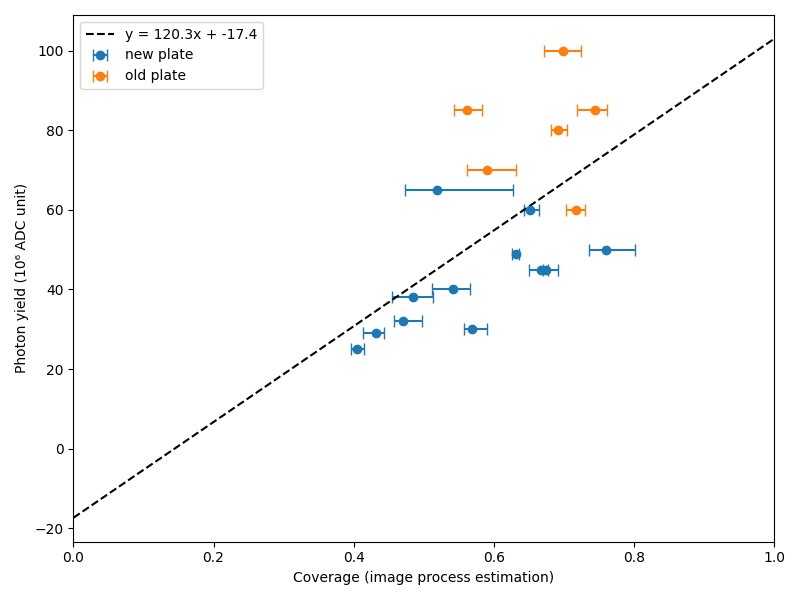

Photon comparison: 18 plates; 0 missing photon yields.
Linear fit: y = 120.3202x + -17.3675; R² = 0.3499


In [8]:
# Cell 8: Compare cluster-based plate coverage with photon yield (original Cell 6).
# Error bars: leave-one-image-out mean ranges, not confidence intervals.
from coverage_analysis import plot_photon_yield

plot_photon_yield(RUN_DIR, PHOTON_YIELD_PATH)